In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
df = pd.read_csv("../lu2_datasets/Extra_Leescatalogus_Opgeschoond.csv")

In [2]:
df.describe()
#df.info()

,Aantal_paginas,Geschatte_leestijd_min,Woordenaantal_omschrijving,Gem_woordlengte,Gem_zinslengte_woorden,Aandeel_lange_woorden_pct,Aantal_zinnen,Leescomplexiteit_score,Publicatiejaar,Gemiddelde_beoordeling
count,255.000000,274.000000,283.000000,283.000000,265.000000,283.000000,283.000000,277.000000,212.000000,183.000000
mean,184.996078,377.343066,14.844523,7.217244,8.230189,42.430035,1.689046,45.813718,2015.622642,3.273770
std,112.073215,263.985609,7.469360,3.972142,3.884682,21.840599,0.463704,12.202466,8.886278,0.352963
min,1.000000,5.000000,1.000000,4.330000,1.000000,0.000000,1.000000,14.900000,1998.000000,2.200000
25%,118.500000,171.000000,5.000000,5.730000,4.000000,28.600000,1.000000,36.600000,2013.000000,3.000000
50%,185.000000,366.000000,17.000000,6.350000,9.000000,35.000000,2.000000,45.400000,2018.000000,3.300000
75%,265.500000,587.500000,20.000000,7.595000,10.000000,50.000000,2.000000,52.200000,2023.000000,3.500000
max,400.000000,946.000000,32.000000,54.000000,26.000000,100.000000,2.000000,80.200000,2025.000000,4.000000


In [3]:
# Alle numerieke kolommen
num = df.select_dtypes(include=["number"])

# Alle categorische/tekstuele kolommen
cat = df.select_dtypes(include=["object", "category"])

/var/folders/64/sqwyjtfn7cv4kj35pqkzbg300000gn/T/ipykernel_6625/3543948782.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat = df.select_dtypes(include=["object", "category"])


In [4]:
num.agg(["max", "min", "mean", "median", "std"]).T

,max,min,mean,median,std
Aantal_paginas,400.0,1.00,184.996078,185.00,112.073215
Geschatte_leestijd_min,946.0,5.00,377.343066,366.00,263.985609
Woordenaantal_omschrijving,32.0,1.00,14.844523,17.00,7.469360
Gem_woordlengte,54.0,4.33,7.217244,6.35,3.972142
Gem_zinslengte_woorden,26.0,1.00,8.230189,9.00,3.884682
Aandeel_lange_woorden_pct,100.0,0.00,42.430035,35.00,21.840599
Aantal_zinnen,2.0,1.00,1.689046,2.00,0.463704
Leescomplexiteit_score,80.2,14.90,45.813718,45.40,12.202466
Publicatiejaar,2025.0,1998.00,2015.622642,2018.00,8.886278
Gemiddelde_beoordeling,4.0,2.20,3.273770,3.30,0.352963


**Outliers**

In [5]:
from scipy import stats

z_scores = stats.zscore(num, nan_policy="omit")

outliers_z = (abs(z_scores) > 3)

print(outliers_z.sum())

10


In [6]:
Q1 = num.quantile(0.25)
Q3 = num.quantile(0.75)

IQR = Q3 - Q1

ondergrens = Q1 - 1.5 * IQR
bovengrens = Q3 + 1.5 * IQR

outliers_iqr = (
    (num < ondergrens) |
    (num > bovengrens)
)

print(outliers_iqr.sum())

Aantal_paginas                 0
Geschatte_leestijd_min         0
Woordenaantal_omschrijving     0
Gem_woordlengte               19
Gem_zinslengte_woorden         4
Aandeel_lange_woorden_pct     23
Aantal_zinnen                  0
Leescomplexiteit_score         4
Publicatiejaar                 0
Gemiddelde_beoordeling         1
dtype: int64


In [26]:
for kolom in num.columns:
    outliers = df.loc[outliers_iqr[kolom], kolom]

    if not outliers.empty:
        print(f"\n{kolom}:")
        print(outliers)


Gem_woordlengte:
0      23.48
37     30.84
74     26.52
111    25.24
143    11.00
144    13.67
148    54.00
160    10.67
163    12.00
169    10.67
175    10.67
179    11.67
180    11.00
199    10.75
250    10.75
251    10.67
261    11.00
269    12.00
274    11.00
Name: Gem_woordlengte, dtype: float64

Gem_zinslengte_woorden:
64     26.0
65     20.0
70     21.0
125    21.0
Name: Gem_zinslengte_woorden, dtype: float64

Aandeel_lange_woorden_pct:
143    100.0
144    100.0
148    100.0
149    100.0
150    100.0
160    100.0
163    100.0
169    100.0
175    100.0
179    100.0
180    100.0
181    100.0
191    100.0
192    100.0
221    100.0
230    100.0
237    100.0
243    100.0
250    100.0
251    100.0
261    100.0
269    100.0
274    100.0
Name: Aandeel_lange_woorden_pct, dtype: float64

Leescomplexiteit_score:
144    80.2
148    78.1
163    76.5
179    75.8
Name: Leescomplexiteit_score, dtype: float64

Gemiddelde_beoordeling:
141    2.2
Name: Gemiddelde_beoordeling, dtype: float64


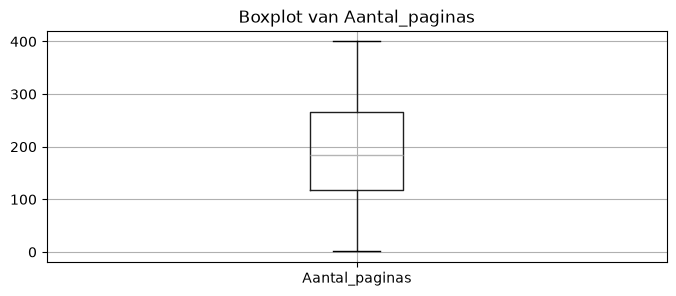

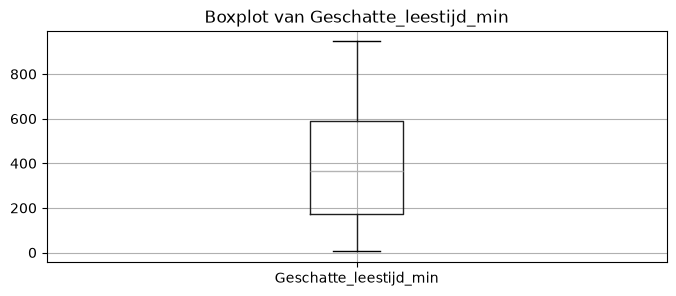

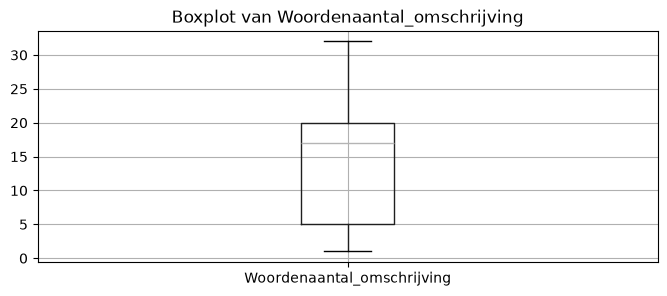

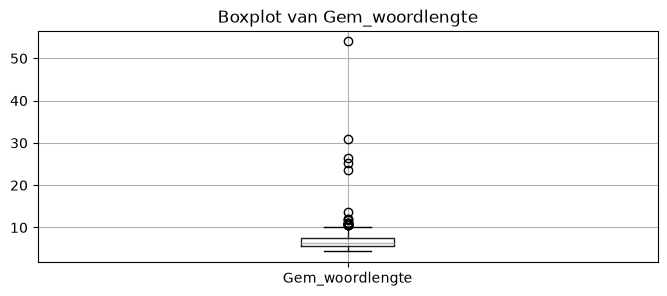

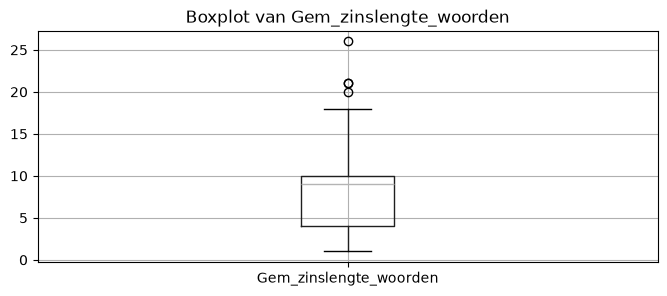

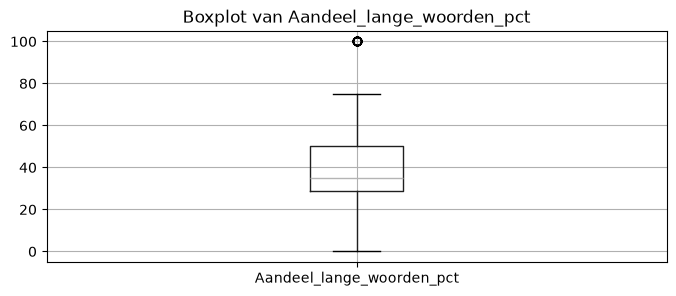

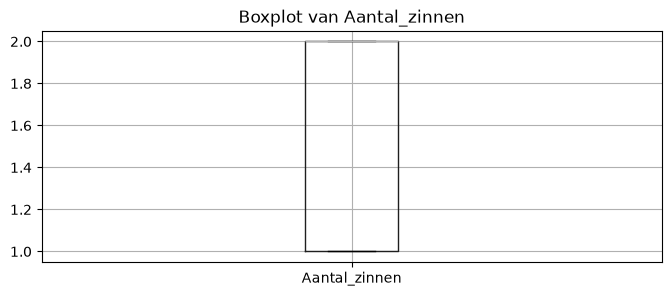

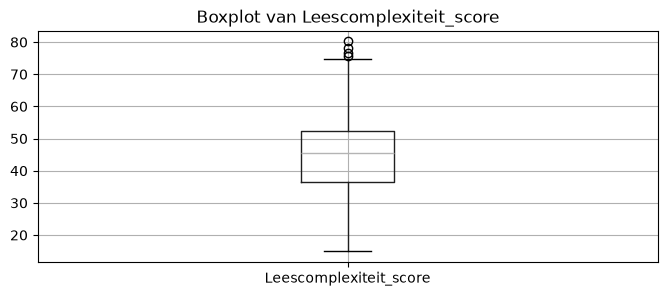

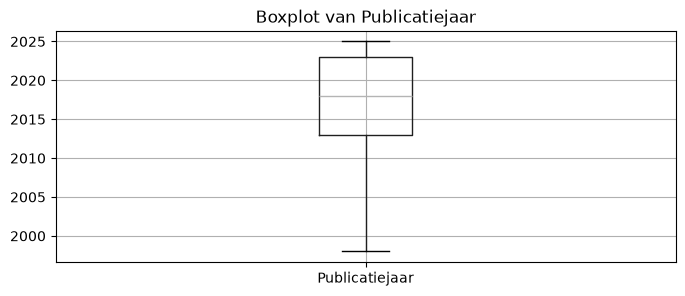

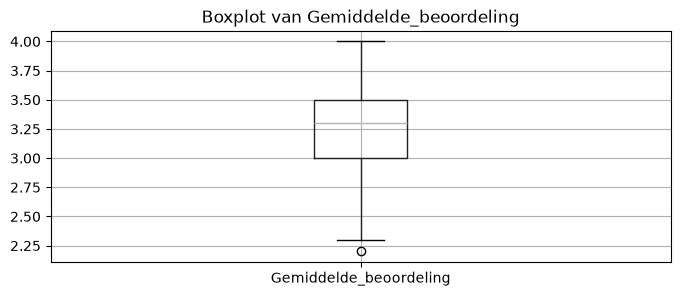

In [27]:
import matplotlib.pyplot as plt

for kolom in num.columns:
    plt.figure(figsize=(8, 3))
    num.boxplot(column=kolom)
    plt.title(f"Boxplot van {kolom}")
    plt.show()

In [28]:
kolommen = [
    "Aantal_paginas",
    "Geschatte_leestijd_min",
    "Gem_zinslengte_woorden",
    "Aandeel_lange_woorden_pct",
    "Leescomplexiteit_score",
    "Gemiddelde_beoordeling"
]

df_outlier = df[kolommen].copy()

In [29]:
# Q1 en Q3 berekenen
Q1 = df_outlier.quantile(0.25)
Q3 = df_outlier.quantile(0.75)

# IQR berekenen
IQR = Q3 - Q1

# Onder- en bovengrens berekenen
ondergrens = Q1 - (1.5 * IQR)
bovengrens = Q3 + (1.5 * IQR)

In [30]:
outliers = (
    (df_outlier < ondergrens) |
    (df_outlier > bovengrens)
)

print("Aantal outliers per kolom:")
print(outliers.sum())

Aantal outliers per kolom:
Aantal_paginas                0
Geschatte_leestijd_min        0
Gem_zinslengte_woorden        4
Aandeel_lange_woorden_pct    23
Leescomplexiteit_score        4
Gemiddelde_beoordeling        1
dtype: int64


In [31]:
df.Aantal_paginas.unique()

array([265., 171., 219., 288., 358.,  nan, 162., 388., 142., 251., 168.,
       160., 206., 157., 323., 236., 130., 348., 178., 266., 305., 112.,
       150., 339., 218., 347., 380., 255., 284., 354., 153., 311., 244.,
       292., 357., 315., 234., 189., 368., 179., 353., 183.,  72., 173.,
       240., 351., 149., 175., 341., 272., 119., 154., 124., 113., 200.,
       143., 346., 110., 264., 208.,  96., 195., 192., 141., 308., 214.,
       386., 239., 367., 211., 228.,  80., 185., 317., 301., 140., 169.,
       369., 344., 256., 254., 329., 294., 136., 275., 114., 198., 250.,
        90., 152., 233.,  77., 148., 205., 155., 335., 106., 319., 131.,
       120., 257., 343., 225.,   5.,   2.,   6.,   4.,   8.,   3.,   9.,
         1., 158., 241., 299., 111., 287.,  83., 231., 165., 302., 248.,
       297.,   7., 242., 222., 147., 146., 400., 213., 246., 176., 269.,
       133., 307., 303., 172., 384., 161., 197., 184., 138., 187., 326.,
       203.,  60., 263., 104., 295., 174., 286., 29